In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [75]:
import os

print(os.getcwd())
print(os.listdir("data"))

c:\Users\Sneha Mishra\OneDrive\Desktop\Customer_churn_prediction
['archive', 'archive.zip', 'WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [76]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (7043, 21)


In [77]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [78]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [79]:
df.describe().T #Statistical summary of numerical features

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [80]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [81]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [82]:
(df.astype(str).apply(
    lambda col: 
col.str.strip()).eq("")).sum()
#Check for empty strings in the dataset
#spaces count is not counted as null values, so we need to check for empty strings as well


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [83]:
print(df.dtypes)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [84]:
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [85]:
print(df["Churn"].value_counts(normalize=True)*100) #Percentage of churned and non-churned customers

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [86]:
blank_charges = df[df["TotalCharges"].astype(str).str.strip().eq("")]

blank_charges[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


from the above data we understood that the these customers have 0 tenure that means these are new customers so there total charges has not been recorded. 
we will create all 11 blank values to actual missing values

In [87]:
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing Totalcharges:", df["TotalCharges"].isnull().sum())

Missing Totalcharges: 11


In [88]:
print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isnull().sum())

float64
11


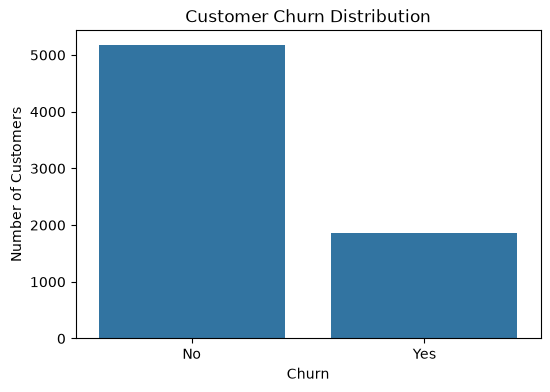

In [89]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [90]:
#customers kitne time se comapany ke sath hai and unka monthly charges kya hai, aur unhone total kitna pay kiya hai

df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


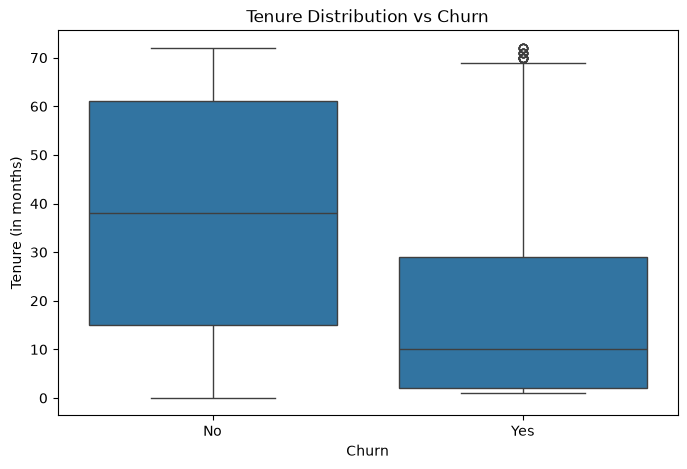

In [91]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure Distribution vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (in months)")
plt.show()

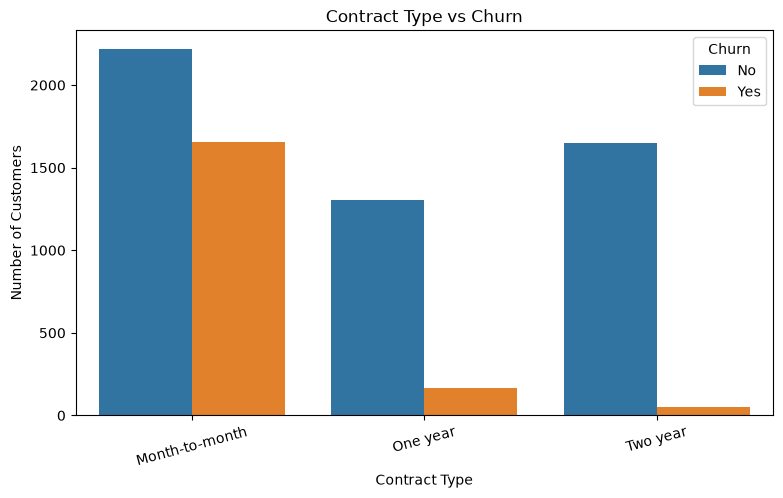

In [92]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

In [93]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [94]:
x = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"Yes": 1, "No": 0}) #Convert target variable to binary

print("Features shape:", x.shape)
print("Target shape:", y.shape)

print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)
Churn
0    5174
1    1869
Name: count, dtype: int64


In [95]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

x_train shape: (5634, 19)
x_test shape: (1409, 19)
y_train shape: (5634,)
y_test shape: (1409,)


In [96]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

In [97]:
numerical_features = x.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = x.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Numerical features:", numerical_features)
print("no. of numerical features:", len(numerical_features))

print("Categorical features:", categorical_features)
print("no. of categorical features:", len(categorical_features))


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
no. of numerical features: 4
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
no. of categorical features: 15


C:\Users\Sneha Mishra\AppData\Local\Temp\ipykernel_19484\4019061013.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = x.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


In [98]:
#numerical preprocessing pipeline
numerical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

In [99]:
#categorical preprocessing pipeline
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))])

In [100]:
#combine both
preprocessor = ColumnTransformer([("num", numerical_pipeline, numerical_features), ("cat", categorical_pipeline, categorical_features)])

In [101]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",
LogisticRegression(max_iter=1000))
])

In [102]:
model.fit(x_train, y_train)

print("Model training completed!")

Model training completed!


In [103]:
y_pred = model.predict(x_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("First 10 predicted values:")
print(y_pred[:10].tolist())

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
First 10 predicted values:
[0, 1, 0, 0, 0, 1, 0, 0, 0, 0]


In [104]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

print("\nclassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8055358410220014
precision: 0.6572327044025157
Recall: 0.5588235294117647
F1-Score: 0.6040462427745664

classification report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



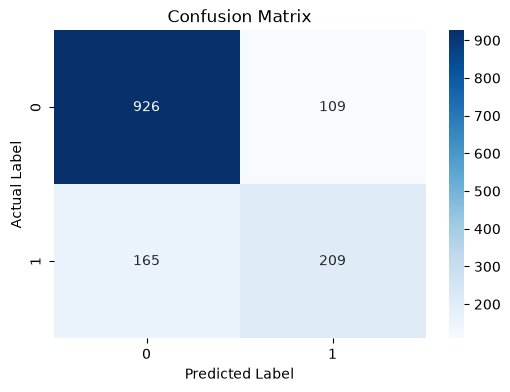

In [105]:
#confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

#RandomForest

In [106]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("Classifier",
RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
))
])

rf_model.fit(x_train, y_train)

print("Random forest training completed!")



Random forest training completed!


In [107]:
y_pred_rf = rf_model.predict(x_test)

print("first 10 actual values:")
print(y_test.iloc[:10].tolist())

print("first 10 random forest predictions:")
print(y_pred_rf[:10].tolist())

first 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
first 10 random forest predictions:
[0, 1, 0, 0, 0, 1, 0, 0, 0, 1]


In [108]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("Random Forest Precision:",
      round(precision_score(y_test, y_pred_rf), 4))

print("Random Forest Recall:",
      round(recall_score(y_test, y_pred_rf), 4))

print("Random Forest F1-score:",
      round(f1_score(y_test, y_pred_rf), 4))

Random Forest Accuracy: 0.7637
Random Forest Precision: 0.5485
Random Forest Recall: 0.6203
Random Forest F1-score: 0.5822


In [109]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_rf)
    ]
})

results.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,Random Forest,0.7637,0.5485,0.6203,0.5822


In [110]:
#we will try cross validation now, tuning the random model for better result

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_tuned = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_tuned.fit(x_train, y_train)

y_pred_tuned = rf_tuned.predict(x_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_tuned), 4))
print("F1-score:", round(f1_score(y_test, y_pred_tuned), 4))



Accuracy: 0.7559
Precision: 0.5275
Recall: 0.7701
F1-score: 0.6261


In [111]:
#now instead of tuning RF more , lets tune the logistic regression now
#default threshold = 0.5

y_prob_lr = model.predict_proba(x_test)[:, 1]

print(y_prob_lr[:10])

[0.04529387 0.68441126 0.05872074 0.40170424 0.02154772 0.60393536
 0.44922498 0.13005522 0.00288077 0.39517899]


In [112]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

for threshold in [0.3, 0.4, 0.5, 0.6]:
    pred = (y_prob_lr >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(accuracy_score(y_test, pred), 3))
    print("Precision:", round(precision_score(y_test, pred), 3))
    print("Recall:", round(recall_score(y_test, pred), 3))
    print("F1-score:", round(f1_score(y_test, pred), 3))


Threshold: 0.3
Accuracy: 0.749
Precision: 0.519
Recall: 0.754
F1-score: 0.615

Threshold: 0.4
Accuracy: 0.778
Precision: 0.569
Recall: 0.668


F1-score: 0.615

Threshold: 0.5
Accuracy: 0.806
Precision: 0.657
Recall: 0.559
F1-score: 0.604

Threshold: 0.6
Accuracy: 0.799
Precision: 0.718
Recall: 0.401
F1-score: 0.515


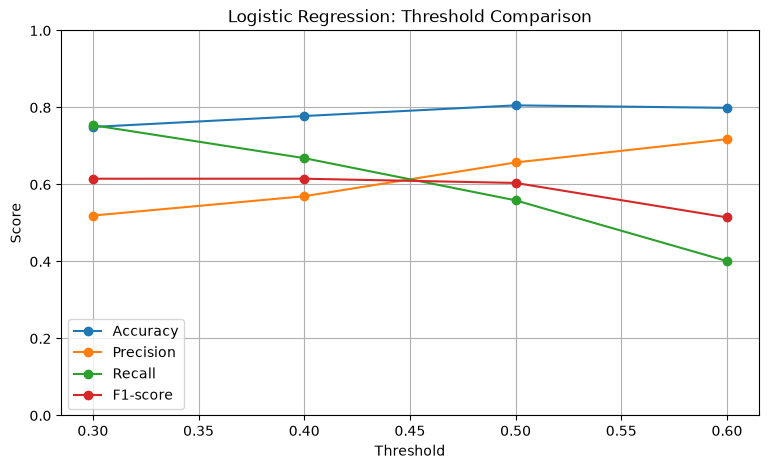

In [113]:
thresholds = [0.3, 0.4, 0.5, 0.6]

accuracy_values = []
precision_values = []
recall_values = []
f1_values = []

for threshold in thresholds:
    pred = (y_prob_lr >= threshold).astype(int)

    accuracy_values.append(accuracy_score(y_test, pred))
    precision_values.append(precision_score(y_test, pred))
    recall_values.append(recall_score(y_test, pred))
    f1_values.append(f1_score(y_test, pred))

metrics_df = pd.DataFrame({
    "Threshold": thresholds,
    "Accuracy": accuracy_values,
    "Precision": precision_values,
    "Recall": recall_values,
    "F1-score": f1_values
})

metrics_df.set_index("Threshold").plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Logistic Regression: Threshold Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

In [114]:
threshold = 0.45

y_pred_045 = (y_prob_lr >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_test, y_pred_045), 4))
print("Precision:", round(precision_score(y_test, y_pred_045), 4))
print("Recall:", round(recall_score(y_test, y_pred_045), 4))
print("F1-score:", round(f1_score(y_test, y_pred_045), 4))

Threshold: 0.45
Accuracy: 0.7892
Precision: 0.6005
Recall: 0.615
F1-score: 0.6077


In [115]:
#Stratified cv on the training data

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = cross_validate(
    model,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} +/- {scores.std():.3f}"
    )

Accuracy: 0.802 +/- 0.012
Precision: 0.653 +/- 0.025
Recall: 0.543 +/- 0.041
F1: 0.592 +/- 0.030


In [116]:
#lets train logistic regresseon with balanced weight

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model_balanced.fit(x_train, y_train)

y_pred_balanced = model_balanced.predict(x_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_balanced), 4))
print("Precision:", round(precision_score(y_test, y_pred_balanced), 4))
print("Recall:", round(recall_score(y_test, y_pred_balanced), 4))
print("F1-score:", round(f1_score(y_test, y_pred_balanced), 4))

Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1-score: 0.6136


In [117]:
#cv on balanced logistic regression

cv_balanced = cross_validate(
    model_balanced,
    x_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = cv_balanced[f"test_{metric}"]
    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} +/- {scores.std():.3f}"
    )

Accuracy: 0.748 +/- 0.015
Precision: 0.516 +/- 0.019
Recall: 0.801 +/- 0.038
F1: 0.628 +/- 0.023


In [118]:
#compare all the model's result

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Tuned Random Forest"
    ],
    "Accuracy": [0.802, 0.748, 0.756],
    "Precision": [0.653, 0.516, 0.528],
    "Recall": [0.543, 0.801, 0.770],
    "F1-score": [0.592, 0.628, 0.626]
})

model_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.802,0.653,0.543,0.592
1,Balanced Logistic Regression,0.748,0.516,0.801,0.628
2,Tuned Random Forest,0.756,0.528,0.770,0.626


In [119]:
#stratified cv on all three models then we will compare

from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": model,
    "Balanced Logistic Regression": model_balanced,
    "Tuned Random Forest": rf_tuned
}

comparison_results = []

for name, estimator in models.items():
    scores = cross_validate(
        estimator,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    comparison_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean()
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.802,0.653,0.543,0.592
1,Balanced Logistic Regression,0.748,0.516,0.801,0.628
2,Tuned Random Forest,0.764,0.539,0.763,0.631


In [120]:
#we will try XGBOOST OR Gradient boosting

# Feature importance from tuned Random Forest
rf_model = rf_tuned.fit(x_train, y_train)

feature_importance = rf_model.named_steps["classifier"].feature_importances_

feature_names = (
    rf_model.named_steps["preprocessor"].get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
}).sort_values("Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
36,cat__Contract_Month-to-month,0.126691
1,num__tenure,0.123822
3,num__TotalCharges,0.103632
2,num__MonthlyCharges,0.070217
38,cat__Contract_Two year,0.065198
18,cat__OnlineSecurity_No,0.058637
16,cat__InternetService_Fiber optic,0.051101
27,cat__TechSupport_No,0.047362
43,cat__PaymentMethod_Electronic check,0.036572
37,cat__Contract_One year,0.020620


In [121]:
#gradient boosting

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(x_train, y_train)

y_pred_gb = gb_model.predict(x_test)

print("Gradient Boosting Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_gb), 3))
print("Precision:", round(precision_score(y_test, y_pred_gb), 3))
print("Recall:", round(recall_score(y_test, y_pred_gb), 3))
print("F1-score:", round(f1_score(y_test, y_pred_gb), 3))

Gradient Boosting Results
Accuracy: 0.806
Precision: 0.676
Recall: 0.513
F1-score: 0.584


In [122]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [123]:
#xgboost 

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(x_train, y_train)

y_pred_xgb = xgb_model.predict(x_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 3))
print("Precision:", round(precision_score(y_test, y_pred_xgb), 3))
print("Recall:", round(recall_score(y_test, y_pred_xgb), 3))
print("F1-score:", round(f1_score(y_test, y_pred_xgb), 3))

Accuracy: 0.806
Precision: 0.674
Recall: 0.524
F1-score: 0.589


In [124]:
#lets tune the classification threshold for xgboost

from sklearn.metrics import (
    precision_score, recall_score,
    f1_score, accuracy_score
)

y_prob_xgb = xgb_model.predict_proba(x_test)[:, 1]

for threshold in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    y_pred_threshold = (
        y_prob_xgb >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(
        accuracy_score(y_test, y_pred_threshold), 3
    ))
    print("Precision:", round(
        precision_score(y_test, y_pred_threshold, zero_division=0), 3
    ))
    print("Recall:", round(
        recall_score(y_test, y_pred_threshold, zero_division=0), 3
    ))
    print("F1-score:", round(
        f1_score(y_test, y_pred_threshold, zero_division=0), 3
    ))


Threshold: 0.25
Accuracy: 0.744
Precision: 0.512
Recall: 0.81
F1-score: 0.627

Threshold: 0.3
Accuracy: 0.76
Precision: 0.533
Recall: 0.767
F1-score: 0.629

Threshold: 0.35
Accuracy: 0.775
Precision: 0.56
Recall: 0.711
F1-score: 0.627

Threshold: 0.4
Accuracy: 0.785
Precision: 0.584
Recall: 0.663
F1-score: 0.621

Threshold: 0.45
Accuracy: 0.798
Precision: 0.625
Recall: 0.602
F1-score: 0.613

Threshold: 0.5
Accuracy: 0.806
Precision: 0.674
Recall: 0.524
F1-score: 0.589


ROC-AUC: 0.848


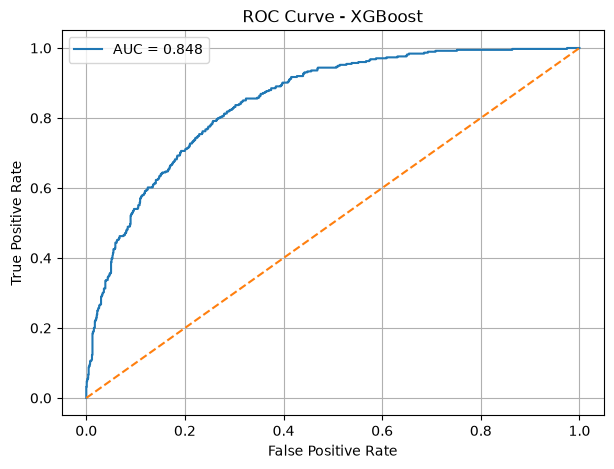

In [125]:
#ROC AND AUC

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)
import matplotlib.pyplot as plt

# Predicted probabilities for churn
y_prob_xgb = xgb_model.predict_proba(x_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test, y_prob_xgb
)

# Calculate AUC
auc_score = roc_auc_score(
    y_test, y_prob_xgb
)

print("ROC-AUC:", round(auc_score, 3))

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.grid(True)
plt.show()

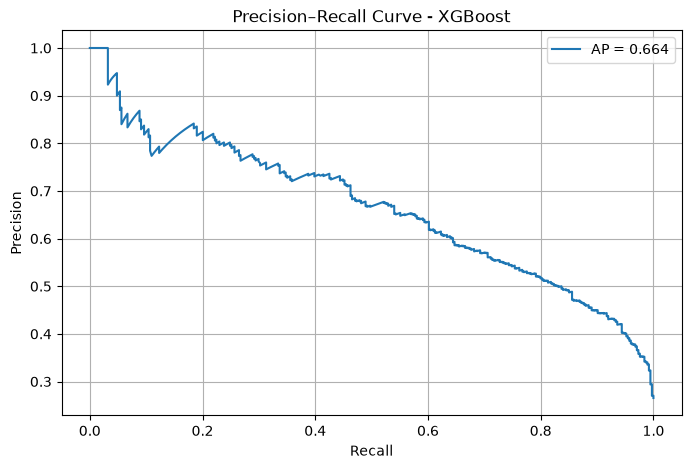

Average Precision: 0.664


In [126]:
#precision recall curve

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Get churn probabilities from XGBoost
y_prob_xgb = xgb_model.predict_proba(x_test)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob_xgb
)

# Calculate Average Precision
ap = average_precision_score(y_test, y_prob_xgb)

# Plot the curve
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"AP = {ap:.3f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve - XGBoost")
plt.legend()
plt.grid(True)
plt.show()

print("Average Precision:", round(ap, 3))

In [127]:
from sklearn.model_selection import cross_validate
import pandas as pd

models = {
    "Logistic Regression": model,
    "Balanced Logistic Regression": model_balanced,
    "Tuned Random Forest": rf_tuned,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

results = []

for name, estimator in models.items():
    scores = cross_validate(
        estimator,
        x_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        }
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.802,0.653,0.543,0.592,0.846
1,Balanced Logistic Regression,0.748,0.516,0.801,0.628,0.846
2,Tuned Random Forest,0.764,0.539,0.763,0.631,0.845
3,Gradient Boosting,0.804,0.666,0.525,0.587,0.849
4,XGBoost,0.807,0.672,0.534,0.595,0.849


Final Model: Tuned Random Forest
Accuracy: 0.756
Precision: 0.527
Recall: 0.77
F1-score: 0.626
ROC-AUC: 0.84

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



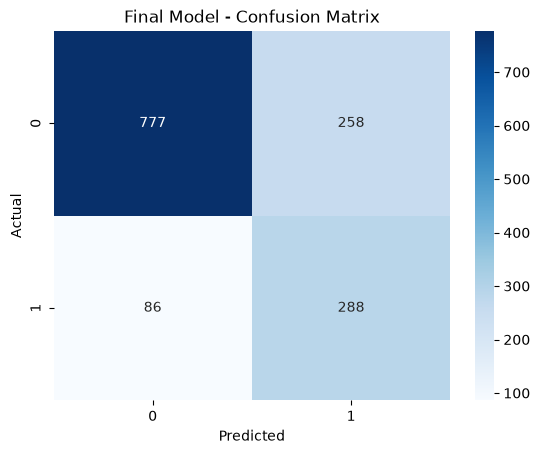

In [128]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

final_model = rf_tuned

# Predict on the unseen test data
y_pred_final = final_model.predict(x_test)
y_prob_final = final_model.predict_proba(x_test)[:, 1]

print("Final Model: Tuned Random Forest")
print("Accuracy:", round(accuracy_score(y_test, y_pred_final), 3))
print("Precision:", round(precision_score(y_test, y_pred_final), 3))
print("Recall:", round(recall_score(y_test, y_pred_final), 3))
print("F1-score:", round(f1_score(y_test, y_pred_final), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_final), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

cm = confusion_matrix(y_test, y_pred_final)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Model - Confusion Matrix")
plt.show()

In [129]:
# Identify the most important churn-related features
feature_importance = rf_tuned.named_steps["classifier"].feature_importances_

feature_names = (
    rf_tuned.named_steps["preprocessor"].get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
}).sort_values("Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
36,cat__Contract_Month-to-month,0.126691
1,num__tenure,0.123822
3,num__TotalCharges,0.103632
2,num__MonthlyCharges,0.070217
38,cat__Contract_Two year,0.065198
18,cat__OnlineSecurity_No,0.058637
16,cat__InternetService_Fiber optic,0.051101
27,cat__TechSupport_No,0.047362
43,cat__PaymentMethod_Electronic check,0.036572
37,cat__Contract_One year,0.020620


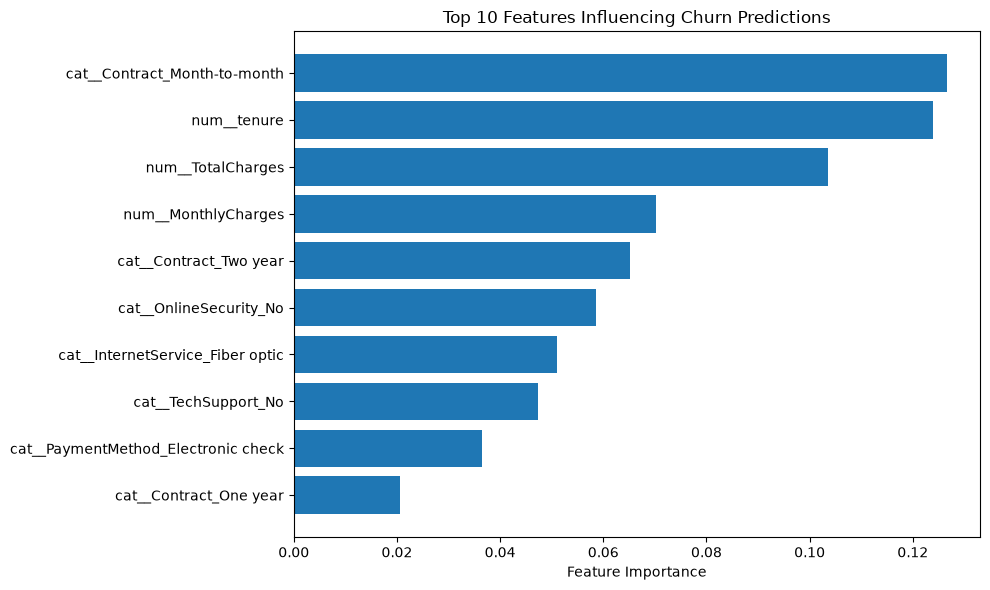

In [130]:
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features Influencing Churn Predictions")
plt.tight_layout()
plt.show()

In [131]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/customer_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [132]:
os.makedirs("reports", exist_ok=True)

importance_df.to_csv(
    "reports/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [133]:
import joblib
import pandas as pd
import os

# Check saved files
print("Model exists:", os.path.exists("models/customer_churn_model.pkl"))
print("Feature importance exists:", os.path.exists("reports/feature_importance.csv"))

# Load the saved model
loaded_model = joblib.load("models/customer_churn_model.pkl")

# Predict on sample customers
sample_customers = x_test.iloc[:5]
predictions = loaded_model.predict(sample_customers)
probabilities = loaded_model.predict_proba(sample_customers)[:, 1]

results = pd.DataFrame({
    "Actual Churn": y_test.iloc[:5].values,
    "Predicted Churn": predictions,
    "Churn Probability": probabilities.round(3)
})

results

Model exists: True
Feature importance exists: True


,Actual Churn,Predicted Churn,Churn Probability
0,0,0,0.016
1,0,1,0.825
2,0,0,0.131
3,0,1,0.506
4,0,0,0.047


In [134]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

print("Final Model: Tuned Random Forest")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_final):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_final):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_final):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred_final):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, final_model.predict_proba(x_test)[:, 1]):.3f}")

Final Model: Tuned Random Forest
Accuracy:  0.756
Precision: 0.527
Recall:    0.770
F1-score:  0.626
ROC-AUC:   0.840
